## Detailed and typical solution (>81% Score)

Hello kagglers ..   

This notebook designed to be as **detailed** as possible solution for the Titanic problem, I tried to make it typical, clear, tidy and **beginner-friendly**. 

If you find this notebook useful press the **upvote** button, This helps me a lot ^-^.  
I hope you find it helpful.

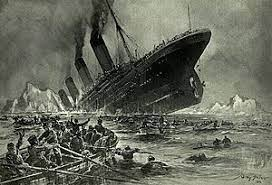

In [1]:
#=======================================================================================
# Importing the libaries:
#=======================================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
warnings.filterwarnings("ignore")

#=======================================================================================

<div style="color:#00ADB5;
           display:fill;
           border-radius:5px;
           background-color:#393E46;
           font-size:20px;
           font-family:sans-serif;
           letter-spacing:0.5px">
        <p style="padding: 10px;
              color:white;">
            <b>1 ) Importing the data:</b>
        </p>
</div>


In [2]:
#=======================================================================================
# Reading the data:
#=======================================================================================

def read_data():
    train_data = pd.read_csv("/kaggle/input/titanic/train.csv")
    print("Train data imported successfully!!")
    print("-"*50)
    test_data = pd.read_csv("/kaggle/input/titanic/test.csv")
    print("Test data imported successfully!!")
    return train_data , test_data

train_data , test_data = read_data()
combine = [train_data , test_data]

#=======================================================================================

Train data imported successfully!!
--------------------------------------------------
Test data imported successfully!!


<div style="color:#00ADB5;
           display:fill;
           border-radius:5px;
           background-color:#393E46;
           font-size:20px;
           font-family:sans-serif;
           letter-spacing:0.5px">
        <p style="padding: 10px;
              color:white;">
            <b> 2 ) Discovering the data:</b>
        </p>
</div>


In [3]:
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
test_data.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [5]:
#=======================================================================================
# Discovering the features:
#=======================================================================================

print("Train data features are:\n")
print(train_data.columns.values)
print('\n' ,"="*80 , '\n')
print("Test data features are:\n")
print(test_data.columns.values)

Train data features are:

['PassengerId' 'Survived' 'Pclass' 'Name' 'Sex' 'Age' 'SibSp' 'Parch'
 'Ticket' 'Fare' 'Cabin' 'Embarked']


Test data features are:

['PassengerId' 'Pclass' 'Name' 'Sex' 'Age' 'SibSp' 'Parch' 'Ticket' 'Fare'
 'Cabin' 'Embarked']


In [6]:
#=======================================================================================
# Discovering the features types:
#=======================================================================================

train_data.info()
print('_'*40 , '\n')
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
________________________________________ 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Passeng

#### Features discovering results:

- Features of the test data are the same as features of the training data except for the Survived feature (because it's the target).
- Features types:
    - Categorical:
        - Pclass (ordinal)
        - Name (nominal)
        - Sex (nominal)
    - Numerical:
        - Age (continuous)
        - Fare (continuous)
        - SibSp (discrete)
        - Parch (discrete)
    - Mixed:
        - Ticket (numeric and alphanumeric)
        - Cabin (alphanumeric)
        
**Insights:** Features types are very important for EDA step.

In [7]:
#=======================================================================================
# Discovering the missed values:
#=======================================================================================

print("Train data missed values:\n")
print(train_data.isnull().sum())
print('\n','_'*40 , '\n')
print("Test data missed values:")
print(test_data.isnull().sum())

Train data missed values:

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

 ________________________________________ 

Test data missed values:
PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64


#### Missed values discovering results:
- Train Data:
    - Age: 177/891 missed values (19.8% are missed).
    - Cabin: 687/891 missed values (77.1% are missed).
    - Embarked: 2/891 missed values.
- Test Data:
    - Age: 86/418 missed values (20.5% are missed).
    - Cabin: 327/418 missed values (78.2% are missed).
    - Fare: 1/418 missed values.
    
**Insights:** Now we know what are the missed values, And we are going to discover the correlations to do what is appropriate.

In [8]:
#=======================================================================================
# Discovering the numerical data distribution :
#=======================================================================================

train_data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


#### Numerical data distribution discovering results:
  - The survival rate for this data is 38.3%.
  - More than 75% of the passengers are below 38 years old.
  - There are too few old passengers.
  - Most passengers travel alone.
  - There are a few outliers in the Fare feature.

**insights:**  
  - Age feature has right skewness, So if we are going to fill missing values we will not use the average.
  - There are outliers in Fare, Age, SibSp and Parch features. This inspire us for EDA Step.

In [9]:
#=======================================================================================
# Discovering the categorical data distribution :
#=======================================================================================

train_data.describe(include=['O'])

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,B96 B98,S
freq,1,577,7,4,644


#### Categorical data distribution discovering results:
 - There are no duplicated names.
 - 64.7% of the passengers are males
 - There are duplicated values in the Ticket feature (23.5% are duplicated).
 - There are duplicated values in the Cabin feature (27.9% are duplicated).
 - 72.4% of the passengers used "S" Embarked.

**insights:**
 - Names uniqueness gives us unsight for Data Engineering Step.
 - Duplicate values in Ticket and Cabin features give us insights to make the right decision when filling missed values.
 - we will fill missed Embarked values with 'S' type.

<div style="color:#00ADB5;
           display:fill;
           border-radius:5px;
           background-color:#393E46;
           font-size:20px;
           font-family:sans-serif;
           letter-spacing:0.5px">
        <p style="padding: 10px;
              color:white;">
            <b> 3 ) Exploratory Data Analysis (EDA):</b>
        </p>
</div>



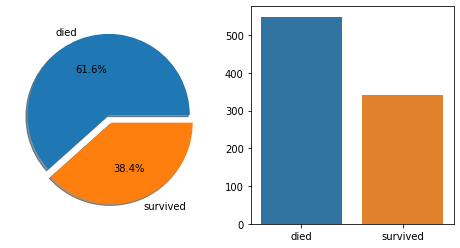

In [10]:
# ===================================================================
# Count of survived
# ===================================================================
f,ax=plt.subplots(1,2,figsize=(8,4))
train_data['Survived'].replace({0:"died",1:"survived"}).value_counts().plot.pie(explode=[0,0.1],autopct='%1.1f%%',ax=ax[0],shadow=True)
ax[0].set_ylabel('')
sns.countplot(x = train_data["Survived"].replace({0:"died",1:"survived"}) , ax = ax[1])
ax[1].set_ylabel('')
ax[1].set_xlabel('')
plt.show()

We saw before that only 338 (38%) of the passengers survived, We need to dig down more to get better insights from the data and see which categories of the passengers did survive and who didn't.



<div style="color:black;
           border-radius:0px;
           background-color:#00ADB5;
           font-size:14px;
           font-family:sans-serif;
           letter-spacing:0.5px">
        <p style="padding: 6px;
              color:white;">
            <b>Discovering the features correlation with Survived:</b>
        </p>
</div>


In [11]:
# Helper functions:
def survived_bar_plot(feature):
    plt.figure(figsize = (6,4))
    sns.barplot(data = train_data , x = feature , y = "Survived").set_title(f"{feature} Vs Survived")
    plt.show()
def survived_table(feature):
    return train_data[[feature, "Survived"]].groupby([feature], as_index=False).mean().sort_values(by='Survived', ascending=False).style.background_gradient(low=0.75,high=1)
def survived_hist_plot(feature):
    plt.figure(figsize = (6,4))
    sns.histplot(data = train_data , x = feature , hue = "Survived",binwidth=5,palette = sns.color_palette(["yellow" , "green"]) ,multiple = "stack" ).set_title(f"{feature} Vs Survived")
    plt.show()

#### Sex Vs Survived:

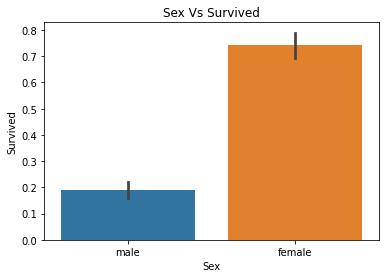

In [12]:
survived_bar_plot('Sex')

In [13]:
survived_table("Sex")

,Sex,Survived
0,female,0.742038
1,male,0.188908


Females have higher Survival rate (74%)

#### Pclass Vs Survived:

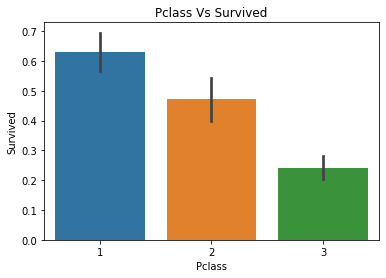

In [14]:
survived_bar_plot("Pclass")

In [15]:
survived_table("Pclass")

,Pclass,Survived
0,1,0.629630
1,2,0.472826
2,3,0.242363


First Pclass passengers are more likely to survive then Seconde Pclass then Third.

#### Embarked:

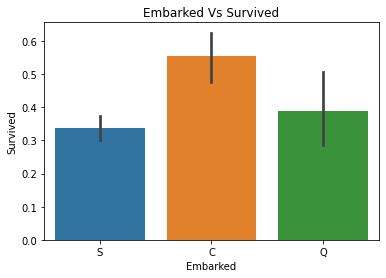

In [16]:
survived_bar_plot("Embarked")

In [17]:
survived_table("Embarked")

,Embarked,Survived
0,C,0.553571
1,Q,0.389610
2,S,0.336957


Passengers who used C Embarked are most likely to survive, Then Q, Then S. (This reasong maybe undirect, I thinks that most of 1 Pclass passengers used C Embarked)

#### Parch:

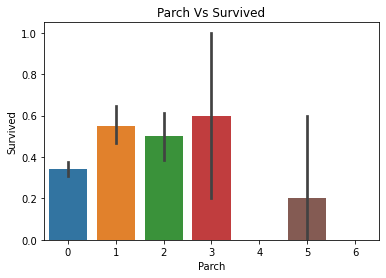

In [18]:
survived_bar_plot("Parch")

In [19]:
survived_table("Parch")

,Parch,Survived
3,3,0.600000
1,1,0.550847
2,2,0.500000
0,0,0.343658
5,5,0.200000
4,4,0.000000
6,6,0.000000


Parch feature has zero correlation for some values, Maybe we can use it to derive more useful feature.

#### SibSp:

In [20]:
survived_table("SibSp")

,SibSp,Survived
1,1,0.535885
2,2,0.464286
0,0,0.345395
3,3,0.250000
4,4,0.166667
5,5,0.000000
6,8,0.000000


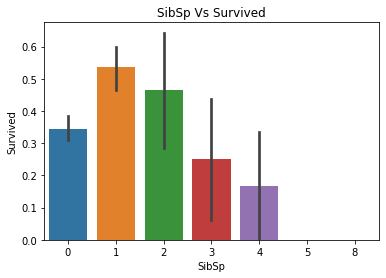

In [21]:
survived_bar_plot("SibSp")

SibSp feature has zero correlation for some values too, Maybe we can use it to derive more useful feature.

#### Age:

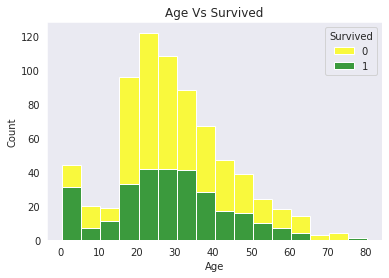

In [22]:
sns.set_style("dark") # to remove the grid.
survived_hist_plot("Age") # Note: This plot is stack plot.

- Infants (age<=5) and childrens (between 10 and 15 years old) are most likely to survive.
- elder passengers (>75) survived.
- most passengers are between 15 and 40 years old.

**insights:** It's good to convert the age feature to age band groups of length 5.

<div style="color:black;
           border-radius:0px;
           background-color:#00ADB5;
           font-size:14px;
           font-family:sans-serif;
           letter-spacing:0.5px">
        <p style="padding: 6px;
              color:white;">
            <b>Discovering the correlation between the features:</b>
        </p>
</div>


<AxesSubplot:>

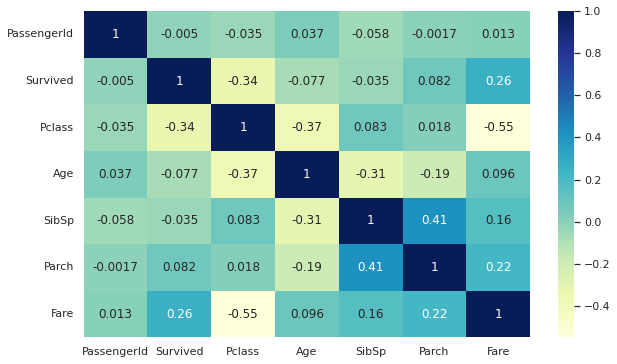

In [23]:
#=======================================================================================
# Discovering the correlations:
#=======================================================================================

sns.set(rc = {'figure.figsize':(10,6)})
sns.heatmap(train_data.corr(), annot = True, fmt='.2g',cmap= 'YlGnBu')

- Passenger Id has no correlation with any feature.
- PClass has strong negative correlation with age and Fare.
- Age has negative correlation with parch and sibsp.

#### Pclass - Age - Survived:

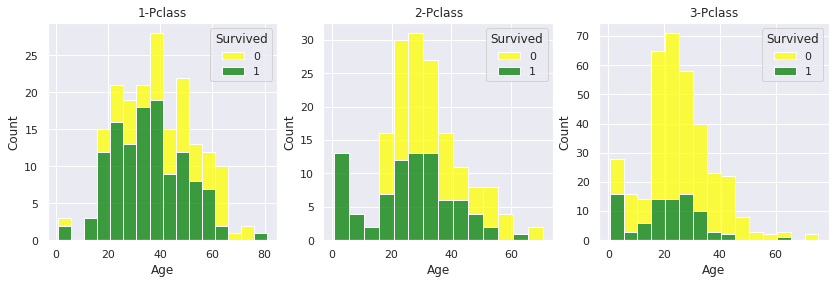

In [24]:
plot , ax = plt.subplots(1 , 3 , figsize=(14,4))
sns.histplot(data = train_data.loc[train_data["Pclass"]==1] , x = "Age" , hue = "Survived",binwidth=5,ax = ax[0],palette = sns.color_palette(["yellow" , "green"]),multiple = "stack").set_title("1-Pclass")
sns.histplot(data = train_data.loc[train_data["Pclass"]==2] , x = "Age" , hue = "Survived",binwidth=5,ax = ax[1],palette = sns.color_palette(["yellow" , "green"]),multiple = "stack").set_title("2-Pclass")
sns.histplot(data = train_data.loc[train_data["Pclass"]==3] , x = "Age" , hue = "Survived",binwidth=5,ax = ax[2],palette = sns.color_palette(["yellow" , "green"]),multiple = "stack").set_title("3-Pclass")
plt.show()

- Pclass=3 had most passengers, Most if them did not survive.
- Infant passengers in Pclass=2 and Pclass=3 mostly survived.
- Most passengers in Pclass=1 survived.

#### Sex - Age - Survived:

Text(0.5, 1.0, 'Females')

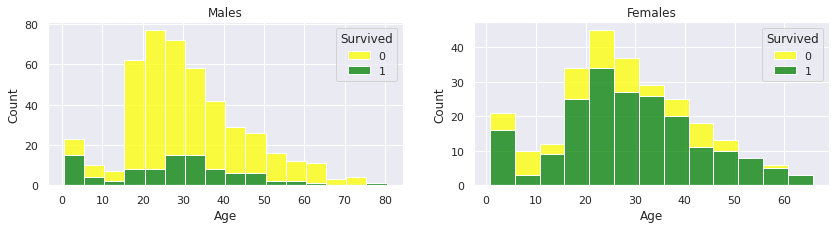

In [25]:
plot , ax = plt.subplots(1 , 2 , figsize=(14,3))
sns.histplot(data = train_data.loc[train_data["Sex"]=="male"] , x = "Age" , hue = "Survived",binwidth=5,ax = ax[0],palette = sns.color_palette(["yellow" , "green"]),multiple = "stack").set_title("Males")
sns.histplot(data = train_data.loc[train_data["Sex"]=="female"] , x = "Age" , hue = "Survived",binwidth=5,ax = ax[1],palette = sns.color_palette(["yellow" , "green"]),multiple = "stack").set_title("Females")

- as we saw before, Females are most likely to survive.
- Elder passengers (>=70) are all males.


<div style="color:#00ADB5;
           display:fill;
           border-radius:5px;
           background-color:#393E46;
           font-size:20px;
           font-family:sans-serif;
           letter-spacing:0.5px">
        <p style="padding: 10px;
              color:white;">
            <b> 4 ) Wrangling The Data:</b>
        </p>
</div>



<div style="color:black;
           border-radius:0px;
           background-color:#00ADB5;
           font-size:14px;
           font-family:sans-serif;
           letter-spacing:0.5px">
        <p style="padding: 6px;
              color:white;">
            <b> Drop unuseful features:</b>
        </p>
</div>


In [26]:
train_data.drop(columns = ["PassengerId"] , inplace = True)

for dataset in combine:
    dataset.drop(columns = ["Ticket" , "Cabin"] , inplace = True)
    
print("Dropping features Done !!")

Dropping features Done !!


<div style="color:black;
           border-radius:0px;
           background-color:#00ADB5;
           font-size:14px;
           font-family:sans-serif;
           letter-spacing:0.5px">
        <p style="padding: 6px;
              color:white;">
            <b>Converting Categorical Features to Numerical and Filling Missed Values:</b>
        </p>
</div>


#### Embarked:

![](http://)

In [27]:
train_data.Embarked.fillna(train_data.Embarked.dropna().max(), inplace=True)
for dataset in combine:
    dataset['Embarked'] = dataset['Embarked'].dropna().map({'S':0,'C':1,'Q':2}).astype(int)

#### Sex:

In [28]:
for dataset in combine:
    dataset['Sex'] = dataset['Sex'].map( {'female': 1, 'male': 0} ).astype(int)    

#### Age:

In [29]:

guess_ages = np.zeros((2,3))

for dataset in combine:
    for i in range(0, 2):
        for j in range(0, 3):
            guess_df = dataset[(dataset['Sex'] == i) & \
                                  (dataset['Pclass'] == j+1)]['Age'].dropna()

            age_guess = guess_df.median()

            # Convert random age float to nearest .5 age
            guess_ages[i,j] = int( age_guess/0.5 + 0.5 ) * 0.5
            
    for i in range(0, 2):
        for j in range(0, 3):
            dataset.loc[ (dataset.Age.isnull()) & (dataset.Sex == i) & (dataset.Pclass == j+1),\
                    'Age'] = guess_ages[i,j]

    dataset['Age'] = dataset['Age'].astype(int)

#### Fare:

In [30]:
test_data.Fare.fillna(test_data.Fare.dropna().median() , inplace= True)

In [31]:
print(train_data.isnull().sum())
print("-" * 50)
print(test_data.isnull().sum())

Survived    0
Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64
--------------------------------------------------
PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked       0
dtype: int64


No more missed values !!

In [32]:
train_data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,"Braund, Mr. Owen Harris",0,22,1,0,7.2500,0
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38,1,0,71.2833,1
2,1,3,"Heikkinen, Miss. Laina",1,26,0,0,7.9250,0
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35,1,0,53.1000,0
4,0,3,"Allen, Mr. William Henry",0,35,0,0,8.0500,0


<div style="color:black;
           border-radius:0px;
           background-color:#00ADB5;
           font-size:14px;
           font-family:sans-serif;
           letter-spacing:0.5px">
        <p style="padding: 6px;
              color:white;">
            <b>Creating Bands:</b>
        </p>
</div>


#### Age Band:

In [33]:
train_data['AgeBand'] = pd.cut(train_data['Age'], 5)
train_data[['AgeBand', 'Survived']].groupby(['AgeBand'], as_index=False).mean().sort_values(by='AgeBand', ascending=True)

,AgeBand,Survived
0,"(-0.08, 16.0]",0.550000
1,"(16.0, 32.0]",0.337374
2,"(32.0, 48.0]",0.412037
3,"(48.0, 64.0]",0.434783
4,"(64.0, 80.0]",0.090909


In [34]:
for dataset in combine:    
    dataset.loc[ dataset['Age'] <= 16, 'Age'] = 0
    dataset.loc[(dataset['Age'] > 16) & (dataset['Age'] <= 32), 'Age'] = 1
    dataset.loc[(dataset['Age'] > 32) & (dataset['Age'] <= 48), 'Age'] = 2
    dataset.loc[(dataset['Age'] > 48) & (dataset['Age'] <= 64), 'Age'] = 3
    dataset.loc[ dataset['Age'] > 64, 'Age']
train_data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,AgeBand
0,0,3,"Braund, Mr. Owen Harris",0,1,1,0,7.2500,0,"(16.0, 32.0]"
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,2,1,0,71.2833,1,"(32.0, 48.0]"
2,1,3,"Heikkinen, Miss. Laina",1,1,0,0,7.9250,0,"(16.0, 32.0]"
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,2,1,0,53.1000,0,"(32.0, 48.0]"
4,0,3,"Allen, Mr. William Henry",0,2,0,0,8.0500,0,"(32.0, 48.0]"


In [35]:
train_data.drop(['AgeBand'], axis=1 , inplace = True)

#### Fare Band:

In [36]:
train_data['FareBand'] = pd.qcut(train_data['Fare'], 4)
train_data[['FareBand', 'Survived']].groupby(['FareBand'], as_index=False).mean().sort_values(by='FareBand', ascending=False)

,FareBand,Survived
3,"(31.0, 512.329]",0.581081
2,"(14.454, 31.0]",0.454955
1,"(7.91, 14.454]",0.303571
0,"(-0.001, 7.91]",0.197309


In [37]:
for dataset in combine:
    dataset.loc[ dataset['Fare'] <= 7.91, 'Fare'] = 0
    dataset.loc[(dataset['Fare'] > 7.91) & (dataset['Fare'] <= 14.454), 'Fare'] = 1
    dataset.loc[(dataset['Fare'] > 14.454) & (dataset['Fare'] <= 31), 'Fare']   = 2
    dataset.loc[ dataset['Fare'] > 31, 'Fare'] = 3
    dataset['Fare'] = dataset['Fare'].astype(int)

train_data.drop(['FareBand'], axis=1 , inplace = True)


In [38]:
train_data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,"Braund, Mr. Owen Harris",0,1,1,0,0,0
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,2,1,0,3,1
2,1,3,"Heikkinen, Miss. Laina",1,1,0,0,1,0
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,2,1,0,3,0
4,0,3,"Allen, Mr. William Henry",0,2,0,0,1,0


<div style="color:black;
           border-radius:0px;
           background-color:#00ADB5;
           font-size:14px;
           font-family:sans-serif;
           letter-spacing:0.5px">
        <p style="padding: 6px;
              color:white;">
            <b>Data Engineering:</b>
        </p>
</div>


#### Family Size:

In [39]:
for dataset in combine:
    dataset['FamilySize'] = dataset['SibSp'] + dataset['Parch'] + 1

train_data.drop(['Parch', 'SibSp'], axis=1 , inplace = True)
test_data.drop(['Parch', 'SibSp'], axis=1 , inplace = True)    

train_data[['FamilySize', 'Survived']].groupby(['FamilySize'], as_index=False).mean().sort_values(by='Survived', ascending=False)


,FamilySize,Survived
3,4,0.724138
2,3,0.578431
1,2,0.552795
6,7,0.333333
0,1,0.303538
4,5,0.200000
5,6,0.136364
7,8,0.000000
8,11,0.000000


In [40]:
# Create new feature of family size
for dataset in combine:
    dataset['Single'] = dataset['FamilySize'].map(lambda s: 1 if s == 1 else 0)
    dataset['SmallF'] = dataset['FamilySize'].map(lambda s: 1 if  s == 2  else 0)
    dataset['MedF'] = dataset['FamilySize'].map(lambda s: 1 if 3 <= s <= 4 else 0)
    dataset['LargeF'] = dataset['FamilySize'].map(lambda s: 1 if s >= 5 else 0)
    
train_data.drop(columns = ["FamilySize"] , inplace = True)
test_data.drop(columns = ["FamilySize"] , inplace = True)

#### Name Title:

In [41]:
for dataset in combine:
    dataset['Title'] = dataset.Name.str.extract(' ([A-Za-z]+)\.', expand=False)

pd.crosstab(train_data['Title'], train_data['Sex'])

Sex,0,1
Title,,
Capt,1,0
Col,2,0
Countess,0,1
Don,1,0
Dr,6,1
Jonkheer,1,0
Lady,0,1
Major,2,0
Master,40,0


In [42]:
for dataset in combine:
    dataset['Title'] = dataset['Title'].replace(['Lady', 'Countess','Capt', 'Col',\
    'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
    dataset['Title'] = dataset['Title'].replace('Mlle', 'Miss')
    dataset['Title'] = dataset['Title'].replace('Ms', 'Miss')
    dataset['Title'] = dataset['Title'].replace('Mme', 'Mrs')
    
train_data[['Title', 'Survived']].groupby(['Title'], as_index=False).mean()

,Title,Survived
0,Master,0.575000
1,Miss,0.702703
2,Mr,0.156673
3,Mrs,0.793651
4,Rare,0.347826


In [43]:
title_mapping = {"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4, "Rare": 5}
for dataset in combine:
    dataset['Title'] = dataset['Title'].map(title_mapping)
    dataset['Title'] = dataset['Title'].fillna(0)


In [44]:
train_data.drop(['Name'], axis=1 , inplace = True)
test_data.drop(['Name'], axis=1 , inplace = True)    

In [45]:
train_data.head()

,Survived,Pclass,Sex,Age,Fare,Embarked,Single,SmallF,MedF,LargeF,Title
0,0,3,0,1,0,0,0,1,0,0,1
1,1,1,1,2,3,1,0,1,0,0,3
2,1,3,1,1,1,0,1,0,0,0,2
3,1,1,1,2,3,0,0,1,0,0,3
4,0,3,0,2,1,0,1,0,0,0,1


In [46]:
test_data.head()

,PassengerId,Pclass,Sex,Age,Fare,Embarked,Single,SmallF,MedF,LargeF,Title
0,892,3,0,2,0,2,1,0,0,0,1
1,893,3,1,2,0,0,0,1,0,0,3
2,894,2,0,3,1,2,1,0,0,0,1
3,895,3,0,1,1,0,1,0,0,0,1
4,896,3,1,1,1,0,0,0,1,0,3


<div style="color:#00ADB5;
           display:fill;
           border-radius:5px;
           background-color:#393E46;
           font-size:20px;
           font-family:sans-serif;
           letter-spacing:0.5px">
        <p style="padding: 10px;
              color:white;">
            <b> 5 ) Modeling:</b>
        </p>
</div>



In [47]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, cross_val_score, StratifiedKFold, learning_curve

In [48]:
# ==================================================================================
# Preparing Data For Training:
# ==================================================================================

Y_train = train_data["Survived"]
X_train = train_data.drop(labels = ["Survived"],axis = 1)
Test = test_data.drop(labels = ["PassengerId"],axis = 1)
print(f"X_train shape is = {X_train.shape}" )
print(f"Y_train shape is = {Y_train.shape}" )
print(f"Test shape is = {Test.shape}" )

X_train shape is = (891, 10)
Y_train shape is = (891,)
Test shape is = (418, 10)


In [49]:
# Cross validate model with Kfold stratified cross val
kfold = StratifiedKFold(n_splits=10)

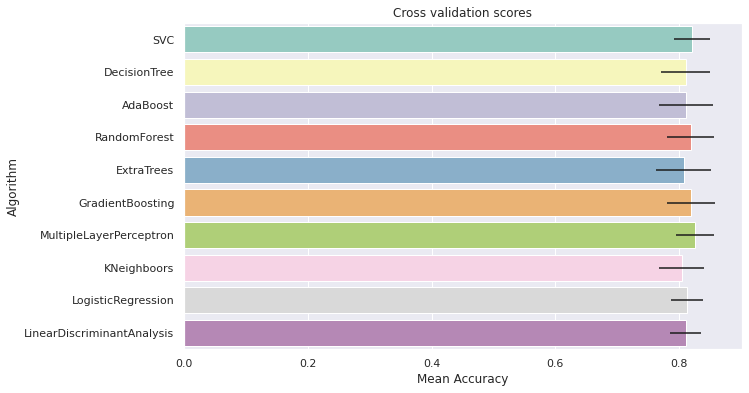

In [50]:
# Modeling step Test differents algorithms 
random_state = 2
classifiers = []
classifiers.append(SVC(random_state=random_state))
classifiers.append(DecisionTreeClassifier(random_state=random_state))
classifiers.append(AdaBoostClassifier(DecisionTreeClassifier(random_state=random_state),random_state=random_state,learning_rate=0.1))
classifiers.append(RandomForestClassifier(random_state=random_state))
classifiers.append(ExtraTreesClassifier(random_state=random_state))
classifiers.append(GradientBoostingClassifier(random_state=random_state))
classifiers.append(MLPClassifier(random_state=random_state))
classifiers.append(KNeighborsClassifier())
classifiers.append(LogisticRegression(random_state = random_state))
classifiers.append(LinearDiscriminantAnalysis())

cv_results = []
for classifier in classifiers :
    cv_results.append(cross_val_score(classifier, X_train, y = Y_train, scoring = "accuracy", cv = kfold, n_jobs=4))

cv_means = []
cv_std = []
for cv_result in cv_results:
    cv_means.append(cv_result.mean())
    cv_std.append(cv_result.std())

cv_res = pd.DataFrame({"CrossValMeans":cv_means,"CrossValerrors": cv_std,"Algorithm":["SVC","DecisionTree","AdaBoost",
"RandomForest","ExtraTrees","GradientBoosting","MultipleLayerPerceptron","KNeighboors","LogisticRegression","LinearDiscriminantAnalysis"]})

g = sns.barplot("CrossValMeans","Algorithm",data = cv_res, palette="Set3",orient = "h",**{'xerr':cv_std})
g.set_xlabel("Mean Accuracy")
g = g.set_title("Cross validation scores")

In [51]:
### META MODELING  WITH ADABOOST, RF, EXTRATREES and GRADIENTBOOSTING

# Adaboost
DTC = DecisionTreeClassifier()

adaDTC = AdaBoostClassifier(DTC, random_state=7)

ada_param_grid = {"base_estimator__criterion" : ["gini", "entropy"],
              "base_estimator__splitter" :   ["best", "random"],
              "algorithm" : ["SAMME","SAMME.R"],
              "n_estimators" :[1,2],
              "learning_rate":  [0.0001, 0.001, 0.01, 0.1, 0.2, 0.3,1.5]}

gsadaDTC = GridSearchCV(adaDTC,param_grid = ada_param_grid, cv=kfold, scoring="accuracy", n_jobs= 4, verbose = 1)

gsadaDTC.fit(X_train,Y_train)

ada_best = gsadaDTC.best_estimator_

gsadaDTC.best_score_

Fitting 10 folds for each of 112 candidates, totalling 1120 fits


0.8159925093632958

In [52]:
#ExtraTrees 
ExtC = ExtraTreesClassifier()


## Search grid for optimal parameters
ex_param_grid = {"max_depth": [None],
              "max_features": [1, 3, 10],
              "min_samples_split": [2, 3, 10],
              "min_samples_leaf": [1, 3, 10],
              "bootstrap": [False],
              "n_estimators" :[100,300],
              "criterion": ["gini"]}


gsExtC = GridSearchCV(ExtC,param_grid = ex_param_grid, cv=kfold, scoring="accuracy", n_jobs= 4, verbose = 1)

gsExtC.fit(X_train,Y_train)

ExtC_best = gsExtC.best_estimator_

# Best score
gsExtC.best_score_

Fitting 10 folds for each of 54 candidates, totalling 540 fits


0.828314606741573

In [53]:
# RFC Parameters tunning 
RFC = RandomForestClassifier()


## Search grid for optimal parameters
rf_param_grid = {"max_depth": [None],
              "max_features": [1, 3, 10],
              "min_samples_split": [2, 3, 10],
              "min_samples_leaf": [1, 3, 10],
              "bootstrap": [False],
              "n_estimators" :[100,300],
              "criterion": ["gini"]}


gsRFC = GridSearchCV(RFC,param_grid = rf_param_grid, cv=kfold, scoring="accuracy", n_jobs= 4, verbose = 1)

gsRFC.fit(X_train,Y_train)

RFC_best = gsRFC.best_estimator_

# Best score
gsRFC.best_score_

Fitting 10 folds for each of 54 candidates, totalling 540 fits


0.8339200998751559

In [54]:
# Gradient boosting tunning

GBC = GradientBoostingClassifier()
gb_param_grid = {'loss' : ["deviance"],
              'n_estimators' : [100,200,300],
              'learning_rate': [0.1, 0.05, 0.01],
              'max_depth': [4, 8],
              'min_samples_leaf': [100,150],
              'max_features': [0.3, 0.1] 
              }

gsGBC = GridSearchCV(GBC,param_grid = gb_param_grid, cv=kfold, scoring="accuracy", n_jobs= 4, verbose = 1)

gsGBC.fit(X_train,Y_train)

GBC_best = gsGBC.best_estimator_

# Best score
gsGBC.best_score_

Fitting 10 folds for each of 72 candidates, totalling 720 fits


0.8226966292134831

In [55]:
### SVC classifier
SVMC = SVC(probability=True)
svc_param_grid = {'kernel': ['rbf'], 
                  'gamma': [ 0.001, 0.01, 0.1, 1],
                  'C': [1, 10, 50, 100,200,300, 1000]}

gsSVMC = GridSearchCV(SVMC,param_grid = svc_param_grid, cv=kfold, scoring="accuracy", n_jobs= 4, verbose = 1)

gsSVMC.fit(X_train,Y_train)

SVMC_best = gsSVMC.best_estimator_

# Best score
gsSVMC.best_score_

Fitting 10 folds for each of 28 candidates, totalling 280 fits


0.8338951310861423

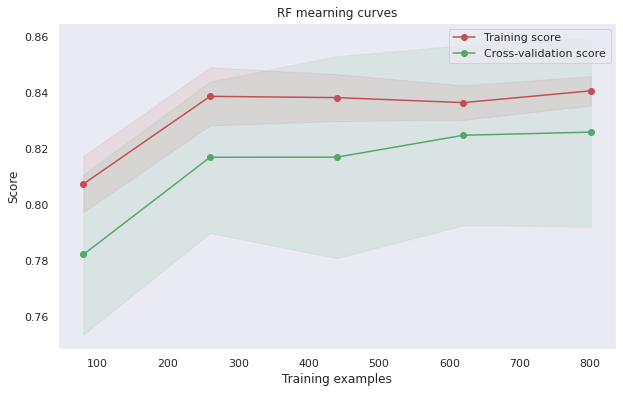

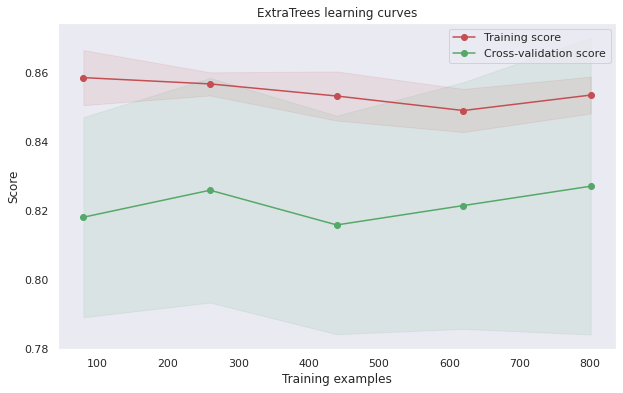

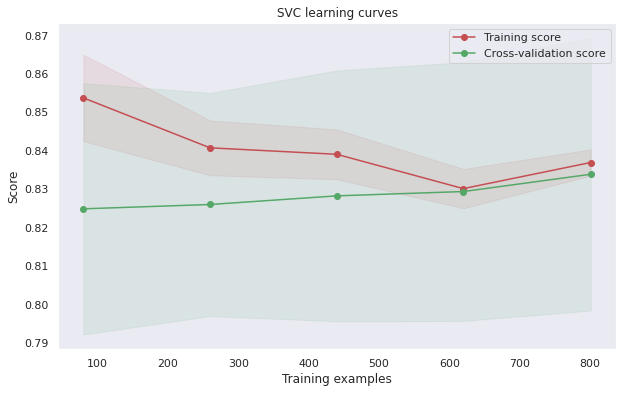

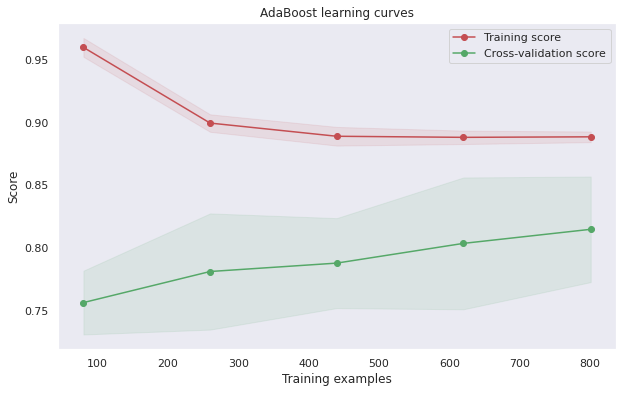

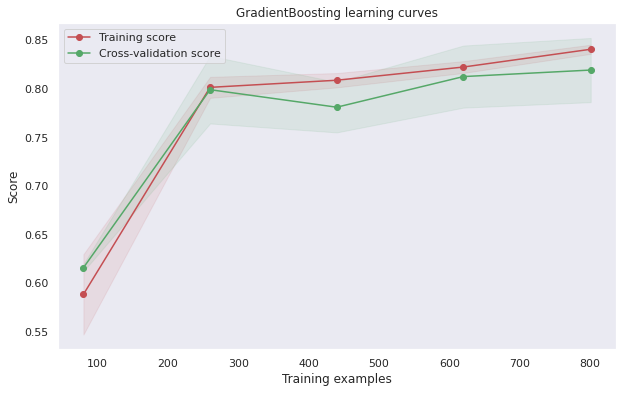

In [56]:
def plot_learning_curve(estimator, title, X, y, ylim=None, cv=None,
                        n_jobs=-1, train_sizes=np.linspace(.1, 1.0, 5)):
    """Generate a simple plot of the test and training learning curve"""
    plt.figure()
    plt.title(title)
    if ylim is not None:
        plt.ylim(*ylim)
    plt.xlabel("Training examples")
    plt.ylabel("Score")
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=train_sizes)
    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)
    plt.grid()

    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.1,
                     color="r")
    plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                     test_scores_mean + test_scores_std, alpha=0.1, color="g")
    plt.plot(train_sizes, train_scores_mean, 'o-', color="r",
             label="Training score")
    plt.plot(train_sizes, test_scores_mean, 'o-', color="g",
             label="Cross-validation score")

    plt.legend(loc="best")
    return plt

g = plot_learning_curve(gsRFC.best_estimator_,"RF mearning curves",X_train,Y_train,cv=kfold)
g = plot_learning_curve(gsExtC.best_estimator_,"ExtraTrees learning curves",X_train,Y_train,cv=kfold)
g = plot_learning_curve(gsSVMC.best_estimator_,"SVC learning curves",X_train,Y_train,cv=kfold)
g = plot_learning_curve(gsadaDTC.best_estimator_,"AdaBoost learning curves",X_train,Y_train,cv=kfold)
g = plot_learning_curve(gsGBC.best_estimator_,"GradientBoosting learning curves",X_train,Y_train,cv=kfold)

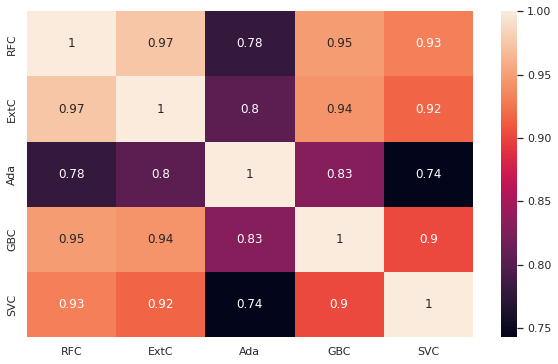

In [57]:
test_Survived_RFC = pd.Series(RFC_best.predict(Test), name="RFC")
test_Survived_ExtC = pd.Series(ExtC_best.predict(Test), name="ExtC")
test_Survived_SVMC = pd.Series(SVMC_best.predict(Test), name="SVC")
test_Survived_AdaC = pd.Series(ada_best.predict(Test), name="Ada")
test_Survived_GBC = pd.Series(GBC_best.predict(Test), name="GBC")

# Concatenate all classifier results
ensemble_results = pd.concat([test_Survived_RFC,test_Survived_ExtC,test_Survived_AdaC,test_Survived_GBC, test_Survived_SVMC],axis=1)
g= sns.heatmap(ensemble_results.corr(),annot=True)

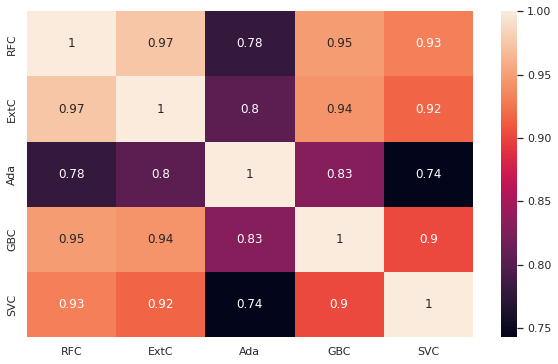

In [58]:

# Concatenate all classifier results
ensemble_results = pd.concat([test_Survived_RFC,test_Survived_ExtC,test_Survived_AdaC,test_Survived_GBC, test_Survived_SVMC],axis=1)


g= sns.heatmap(ensemble_results.corr(),annot=True)

In [59]:
votingC = VotingClassifier(estimators=[('rfc', RFC_best), ('extc', ExtC_best),
('svc', SVMC_best), ('adac',ada_best),('gbc',GBC_best)], voting='soft', n_jobs=4)

votingC = votingC.fit(X_train, Y_train)

In [60]:
test_Survived = pd.Series(votingC.predict(Test), name="Survived")

results = pd.concat([test_data.PassengerId,test_Survived],axis=1)

results.to_csv("ensemble_python_voting.csv",index=False)

#### My Other Useful Notebooks:
- [House Prices - Advanced Regression Problem](https://www.kaggle.com/code/odaymourad/detailed-full-solution-step-by-step-top-3).
- [Spaceship Titanic](https://www.kaggle.com/code/odaymourad/detailed-and-full-solution-step-by-step-80-score).
- [Feature Selection and Data Engineering](https://www.kaggle.com/code/odaymourad/feature-selection-data-engineering-step-by-step).
- [Learn Overfitting and Underfitting](https://www.kaggle.com/code/odaymourad/learn-overfitting-and-underfitting-79-4-score).
- [Random Forest Algorithm](https://www.kaggle.com/code/odaymourad/random-forest-model-clearly-explained).
- [NLP with Disaster tweets](https://www.kaggle.com/code/odaymourad/detailed-and-full-solution-78-4-score).

### References:
- https://www.kaggle.com/code/startupsci/titanic-data-science-solutions
- https://www.kaggle.com/code/yassineghouzam/titanic-top-4-with-ensemble-modeling